# 01 — Cleaning and EDA

**Question:** Can we predict, two hours before scheduled departure, whether a flight will depart at least 15 minutes late?

We study departures from **ATL (Atlanta), DFW (Dallas/Fort Worth), and ORD (Chicago O’Hare)**. Limiting the project to three airports keeps the work manageable while retaining different routes, airlines, and weather conditions.

This notebook reads the source files, checks and cleans flight records, creates the prediction target and basic time features, saves a reusable table, and explores patterns using four graphs. It does not train a model.

The final model uses **40,000 training flights from 2025** and **10,000 test flights from July 2026**. This notebook prepares a much larger source table; Notebook 02 selects the modelling records. The EDA here uses eligible January–September 2025 flights. July has already been evaluated in the original study.

Run from top to bottom. References such as `[20]` identify the saved code-cell execution numbers; they can change if cells are rerun individually.

## Setup: tools and project folder — cells [1]–[4]

| Tool | Role |
|---|---|
| `pathlib` | Locate folders and build file paths |
| `json` | Read configuration and metadata; save the cleaning log |
| `numpy` | Numerical checks and sine/cosine features |
| `pandas` | Read, clean, transform, and save tables |
| `hashlib` | Check downloaded file content with SHA256 |
| `matplotlib` and `seaborn` | Draw and format the four EDA graphs |

The first cells load these tools, locate the project, create the output folder, read configuration, and set the graph style.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

Find the project folder by moving upward until `config/project.json` exists. This allows the notebook to work from either the project root or the notebook folder. If the search reaches the top without finding the configuration, stop with a clear error.

`OUT` is `reports/simple_reproduction/`. Create it if needed so the cleaning checks and later notebook results have a place to be saved. Read `config/project.json` for the source-period definitions, then set a consistent graph style.

In [2]:
ROOT = Path.cwd()
while not (ROOT / 'config/project.json').is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Open this notebook inside the project folder.')
    ROOT = ROOT.parent
OUT = ROOT / 'reports/simple_reproduction'
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
import hashlib
config = json.loads((ROOT / 'config/project.json').read_text())

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

Matplotlib is building the font cache; this may take a moment.


## 1. Sources and optional acquisition — cells [5]–[12]

| Source | Method and role |
|---|---|
| [BTS monthly flight archives](https://transtats.bts.gov/PREZIP/) | Public ZIP downloads containing flight schedules, delays, cancellations, distances, and durations |
| [IEM weather archive](https://mesonet.agron.iastate.edu/request/download.phtml) | Public API requests for weather observations and station metadata, including airport time zones |

No API keys are used. Original URLs, request parameters, and SHA256 checksums are retained in `data/raw/` metadata. Requests run sequentially, use timeouts, and raise HTTP errors.

**Normal runs reuse saved files and need no network access.** `DOWNLOAD_MISSING = False` means a missing required download produces an error explaining how to enable downloading. Set it to `True` only when missing sources need to be obtained.

Weather observations are acquired here but cleaned and joined to flights in Notebook 02. This notebook uses station metadata to obtain time zones.

In [5]:
import zipfile, shutil
DOWNLOAD_MISSING = False

### How the download helpers work

`save_snapshot()` calculates a SHA256 checksum, which acts like a fingerprint of the downloaded bytes. When a saved expected checksum exists, different content raises an error instead of silently replacing the study snapshot.

The payload is first written to a temporary `.part` file. The completed file then replaces the destination, reducing the chance of leaving a partially written input.

`fetch_missing()` skips existing files. For missing files, it checks whether downloading is enabled, requests the source, raises any HTTP error, and saves the response through `save_snapshot()`.

**Existing files are reused without being rehashed by these helpers.** The SHA256 comparison applies to newly downloaded content when an expected checksum is supplied.

In [6]:
def save_snapshot(path, payload, expected):
    digest = hashlib.sha256(payload).hexdigest()
    if expected and digest != expected:
        raise ValueError(f'Source snapshot changed: {path.name}')
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.part')
    temporary.write_bytes(payload)
    temporary.replace(path)

In [7]:
def fetch_missing(path, url, params=None, expected=None):
    if path.exists():
        return
    if not DOWNLOAD_MISSING:
        raise FileNotFoundError(f'{path}: set DOWNLOAD_MISSING=True to download')
    import requests
    response = requests.get(url, params=params, timeout=(20, 180))
    response.raise_for_status()
    save_snapshot(path, response.content, expected)

`extract_csv()` opens a monthly flight ZIP, checks that it contains exactly one CSV, and extracts that member. Reading the complete member also checks its ZIP checksum. Extraction uses a temporary `.csv.part` file before replacing the destination.

In [8]:
def extract_csv(archive, csv):
    with zipfile.ZipFile(archive) as zipped:
        members = [name for name in zipped.namelist() if name.lower().endswith('.csv')]
        assert len(members) == 1
        csv.parent.mkdir(parents=True, exist_ok=True)
        temporary = csv.with_suffix('.csv.part')
        with zipped.open(members[0]) as source, temporary.open('wb') as target:
            shutil.copyfileobj(source, target)
        temporary.replace(csv)

### Why these source months are needed

The notebook reads **17 flight months**:

| Period | Current role |
|---|---|
| November–December 2024 | Earlier flight history for the beginning of 2025 |
| January–December 2025 | Development data and the source of the final training sample |
| May–June 2026 | Earlier flight history needed for July features |
| July 2026 | Source of the final test sample and eligible earlier history |

Notebook 02 calculates features from previous flights, so it needs records outside the selected training and test samples. Loading a month does not mean fitting the model on it. **No 2026 flights are used for model fitting.**

January–April 2026 is archived and is not read. For a missing flight CSV, the next cells reuse a local ZIP if available or download the ZIP before extracting it.

In [9]:
source_months = {2024: [11, 12], 2025: range(1, 13), 2026: [5, 6, 7]}
paths = []
for year, months in source_months.items():
    folder = str(year)
    if year == 2024:
        folder = '2024_context'
    for month in months: 
        filename = f'{year}_{month:02d}.csv'
        paths.append(ROOT / 'data/raw/flights/bts' / folder / 'csv' / filename)
bts_url = 'https://transtats.bts.gov/PREZIP/On_Time_Reporting_Carrier_On_Time_Performance_1987_present'

In [10]:
for csv in paths:
    if csv.exists():
        continue
    archive = csv.parent.parent/'archives'/(csv.stem + '.zip')
    metadata_path = archive.with_suffix('.zip.json')
    metadata = json.loads(metadata_path.read_text()) if metadata_path.exists() else {}
    year, month = map(int, csv.stem.split('_'))
    url = metadata.get('source_url', f'{bts_url}_{year}_{month}.zip')
    fetch_missing(archive, url, expected=metadata.get('sha256'))
    extract_csv(archive, csv)

### Weather and station inputs

There are **39 active weather observation CSVs**: 36 monthly airport files for 2025 and three combined-origin files for May–July 2026. There are also three station metadata files: `GA_ASOS`, `IL_ASOS`, and `TX_ASOS`.

These 42 inputs have request metadata containing the original URL, request parameters, and checksum where recorded. The code checks that the expected 42 metadata records were found, then obtains missing payloads through `fetch_missing()`.

Other station networks and the airport-reference CSV are optional retained references, rather than normal notebook inputs.

In [11]:
weather_folder = ROOT / 'data/raw/weather'
observations = weather_folder / 'observations'
metadata_files = sorted((observations / '2025').glob('*.csv.json'))
metadata_files += sorted((observations / '2026').glob('2026_0[5-7]_origins.csv.json'))
station_networks = ['GA_ASOS', 'IL_ASOS', 'TX_ASOS']
metadata_files += [weather_folder / 'stations' / (name + '.geojson.json')
                   for name in station_networks]
assert len(metadata_files) == 42

In [12]:
for metadata_path in metadata_files:
    metadata = json.loads(metadata_path.read_text())
    request = metadata['request']
    local_file = metadata_path.with_suffix('')
    fetch_missing(local_file, request['url'], request.get('params'), metadata.get('sha256'))

## 2. Read the raw flights — cells [13]–[16]

The national files are large and contain more columns than this project needs. Select 12 source fields and rename them into readable names:

| Saved column | Meaning |
|---|---|
| `flight_date` | Scheduled flight date |
| `airline` | Reporting airline code |
| `flight_number` | Airline’s flight number |
| `origin` | Departure airport |
| `destination` | Arrival airport |
| `scheduled_departure_hhmm` | Scheduled local departure time, such as `1430` |
| `scheduled_duration_minutes` | Planned flight duration |
| `distance_miles` | Route distance |
| `departure_delay_minutes` | Actual departure delay |
| `departure_delay_15_source` | BTS’s existing 15-minute delay indicator |
| `cancelled` | Cancellation indicator |
| `diverted` | Diversion indicator |

Read these fields as strings first so type conversion and cleaning happen explicitly. Flight numbers remain text identifiers, rather than numerical measurements.

In [13]:
SOURCE_COLUMNS = {
    'FlightDate': 'flight_date', 'Reporting_Airline': 'airline',
    'Flight_Number_Reporting_Airline': 'flight_number', 'Origin': 'origin',
    'Dest': 'destination', 'CRSDepTime': 'scheduled_departure_hhmm',
    'CRSElapsedTime': 'scheduled_duration_minutes', 'Distance': 'distance_miles',
    'DepDelay': 'departure_delay_minutes', 'DepDel15': 'departure_delay_15_source',
    'Cancelled': 'cancelled', 'Diverted': 'diverted',
}

### Keep the three airports and preserve source identity

`keep_airports()` filters each chunk to ATL, ORD, and DFW, then adds three provenance fields:

| Field | Why it is saved |
|---|---|
| `source_file` | Trace a record back to its original CSV |
| `source_row_number` | Identify its original CSV row, accounting for the header |
| `flight_id` | Keep a stable identifier across repeated notebook runs |

For example, `2024_11:73` identifies the record at source row 73 in the November 2024 file. The original row position is captured before resetting the table index.

Stable IDs allow later notebooks to select the same training flights and verify that records have not changed.

In [14]:
def keep_airports(chunk, path):
    wanted = chunk['Origin'].str.strip().isin(['ATL', 'ORD', 'DFW'])
    block = chunk.loc[wanted].copy()
    block['source_file'] = path.relative_to(ROOT).as_posix()
    block['source_row_number'] = block.index + 2
    block['flight_id'] = path.stem + ':' + block['source_row_number'].astype(str)
    return block.rename(columns=SOURCE_COLUMNS)

### Read in chunks and stack the retained records

`read_month()` reads **150,000 rows at a time** to limit memory use. It counts all national rows but retains only the three selected origins. The outer loop repeats this for every active month and displays the counts and a preview.

`pd.concat()` stacks chunks and months vertically. This is concatenation; the relational and time joins are performed in Notebook 02.

In the current saved run, the files contain **10,018,886 national records**, of which **1,374,996** depart from the selected airports. `del parts` releases the temporary list after the combined table has been created.

In [15]:
def read_month(path):
    kept = []
    national = 0
    chunks = pd.read_csv(path, usecols=SOURCE_COLUMNS, dtype='string', chunksize=150000)
    for chunk in chunks:
        national += len(chunk)
        kept.append(keep_airports(chunk, path))
    return pd.concat(kept, ignore_index=True), national

In [16]:
parts, source_counts = [], []
for path in paths:
    block, national = read_month(path)
    parts.append(block)
    source_counts.append({'month': path.stem, 'national_rows': national, 'scoped_rows': len(block)})
flights = pd.concat(parts, ignore_index=True)
del parts
display(pd.DataFrame(source_counts), flights.head())

,month,national_rows,scoped_rows
0,2024_11,575404,75647
1,2024_12,590581,77496
2,2025_01,539747,70648
3,2025_02,504884,65498
4,2025_03,600872,78143
5,2025_04,583950,77315
6,2025_05,605648,82443
7,2025_06,611575,85593
8,2025_07,631428,88013
9,2025_08,602378,84534


,flight_date,airline,flight_number,origin,destination,scheduled_departure_hhmm,departure_delay_minutes,departure_delay_15_source,cancelled,diverted,scheduled_duration_minutes,distance_miles,source_file,source_row_number,flight_id
0,2024-11-21,OO,3629,ATL,SHV,1320,-5.00,0.00,0.00,0.00,111.00,551.00,data/raw/flights/bts/2024_context/csv/2024_11.csv,73,2024_11:73
1,2024-11-21,OO,3645,ATL,SHV,2203,-8.00,0.00,0.00,0.00,113.00,551.00,data/raw/flights/bts/2024_context/csv/2024_11.csv,93,2024_11:93
2,2024-11-21,OO,3702,ATL,CRW,0855,-4.00,0.00,0.00,0.00,87.00,363.00,data/raw/flights/bts/2024_context/csv/2024_11.csv,157,2024_11:157
3,2024-11-21,OO,3760,ATL,BQK,1045,-5.00,0.00,0.00,0.00,73.00,238.00,data/raw/flights/bts/2024_context/csv/2024_11.csv,216,2024_11:216
4,2024-11-21,OO,3810,ATL,CRW,2132,-6.00,0.00,0.00,0.00,84.00,363.00,data/raw/flights/bts/2024_context/csv/2024_11.csv,282,2024_11:282


## 3. Types, identities and the prediction target — cells [17]–[21]

The next steps make values consistent, verify that each schedule is identifiable, and define the outcome the model will predict. Unknown outcomes are not guessed, and cancellations are not labelled as on time.

### Clean text and parse dates — cell [17]

Remove surrounding spaces from airline, flight number, origin, and destination. This prevents values such as `"ATL"` and `" ATL "` from acting like different categories. Replace empty labels with missing values.

Convert `flight_date` from `YYYY-MM-DD` text to an actual date with a consistent datetime type. Dates are needed for period selection, calendar features, and timestamp creation.

In [17]:
text_columns = ['airline', 'flight_number', 'origin', 'destination']
for column in text_columns:
    flights[column] = flights[column].str.strip()
    flights[column] = flights[column].replace('', pd.NA)
flights['flight_date'] = pd.to_datetime(flights['flight_date'], format='%Y-%m-%d')
flights['flight_date'] = flights['flight_date'].astype('datetime64[ns]')

### Convert numerical fields — cell [18]

Convert the seven numeric source columns from text to floating-point values. `errors='coerce'` turns unreadable numeric text into missing values. Count failed conversions for the cleaning log; nonfinite values such as infinity are also replaced with missing values.

The current run has **zero unreadable numeric conversions**. A zero count still matters because it shows the check was performed.

In [18]:
numeric_columns = ['scheduled_departure_hhmm', 'scheduled_duration_minutes', 'distance_miles',
                   'departure_delay_minutes', 'departure_delay_15_source', 'cancelled', 'diverted']
conversions = []
for column in numeric_columns:
    original = flights[column]
    values = pd.to_numeric(original, errors='coerce').astype(float)
    failed = original.notna() & values.isna()
    conversions.append({'variable': column, 'unparseable': int(failed.sum())})
    flights[column] = values.where(np.isfinite(values))

### Check identity and missing values — cell [19]

A flight number alone repeats across dates. The schedule identity therefore combines **flight date, airline, flight number, origin, destination, and scheduled departure time**.

The assertions require unique `flight_id` values, no duplicate schedule identities, no missing identity fields, and cancellation indicators restricted to 0 or 1. A failed assertion stops the notebook rather than allowing ambiguous records into modelling.

The missing-value table currently shows **25,669 missing departure delays** and the same number of missing source delay indicators. The other selected source and provenance fields have no missing values. Label eligibility below handles the missing outcomes.

In [19]:
identity = ['flight_date', 'airline', 'flight_number', 'origin', 'destination',
            'scheduled_departure_hhmm']
assert flights['flight_id'].is_unique
assert not flights.duplicated(identity).any()
assert flights[identity].notna().all().all()
assert flights['cancelled'].isin([0, 1]).all()
missing = flights.isna().sum()
display(missing.to_frame('Missing values'))

,Missing values
flight_date,0
airline,0
flight_number,0
origin,0
destination,0
scheduled_departure_hhmm,0
departure_delay_minutes,25669
departure_delay_15_source,25669
cancelled,0
diverted,0


### Create the prediction target — cell [20]

A flight is `label_eligible` only when it is **not cancelled and its departure delay is known**.

| `delayed_departure` | Meaning |
|---|---|
| `0` | Departed less than 15 minutes late, including early departures |
| `1` | Departed at least 15 minutes late |
| Missing | Cancelled or otherwise ineligible for a departure-delay label |

For example, delays of −5, 0, and 14 minutes receive 0; delays of 15 and 60 minutes receive 1. The nullable `Int8` type supports both the small integer labels and missing values.

In binary charts, **“on time” is shorthand for under 15 minutes late**, rather than exactly zero delay. Diversion alone does not exclude a flight because the target concerns departure, and a diverted flight can have a known departure outcome.

In [20]:
operated = flights['cancelled'] == 0
known_delay = flights['departure_delay_minutes'].notna()
flights['label_eligible'] = operated & known_delay
is_delayed = flights['departure_delay_minutes'] >= 15
flights['delayed_departure'] = is_delayed.where(flights['label_eligible'])
flights['delayed_departure'] = flights['delayed_departure'].astype('Int8')

### Verify the target against BTS — cell [21]

Compare the calculated label with `departure_delay_15_source` wherever the flight is eligible and the source label exists. The assertion passes: our labels agree with BTS’s indicator.

Across the full cleaned table, **1,348,218 flights are eligible** and **26,778 are cancelled**. No noncancelled flight has an unknown departure delay.

The cancellation count exceeds the missing-delay count because some cancelled records still contain a delay value. The eligibility rule excludes all cancellations regardless of whether that value is present.

In [21]:
known_source = flights['departure_delay_15_source'].notna()
check_rows = flights['label_eligible'] & known_source
our_labels = flights.loc[check_rows, 'delayed_departure']
source_labels = flights.loc[check_rows, 'departure_delay_15_source']
assert (our_labels == source_labels).all()

## 4. Time conversion and physical-validity checks — cells [22]–[30]

Convert scheduled local times into comparable UTC timestamps, establish when predictions are made, and create basic calendar features. Actual outcome fields are retained for labelling and earlier-flight history; they must not become current-flight predictors.

### Convert HHMM to minutes — cell [22]

`1430` represents 14:30, rather than an ordinary measurement. Separate the hours and minutes:

`14 × 60 + 30 = 870 minutes after midnight`.

Before converting, check that the input is a whole number between 0000 and 2359 and that its minute component is below 60. Save the result as `scheduled_departure_minutes` using a small integer type.

In [22]:
clock = flights['scheduled_departure_hhmm']
hours = clock // 100
minutes = clock % 100
assert (clock % 1 == 0).all()
assert clock.between(0, 2359).all()
assert (minutes < 60).all()
flights['scheduled_departure_minutes'] = (hours * 60 + minutes).astype('int16')

### Build the local timestamp — cell [23]

Convert minutes after midnight into a time duration and add it to `flight_date`. This produces the scheduled local date and time. Prepare an empty UTC timestamp column for the next conversion step; airport-specific time zones still need to be attached.

In [23]:
time_since_midnight = pd.to_timedelta(flights['scheduled_departure_minutes'], unit='m')
local = flights['flight_date'] + time_since_midnight
empty_times = pd.Series(pd.NaT, index=flights.index, dtype='datetime64[ns, UTC]')
flights['scheduled_departure_utc'] = empty_times

### Read airport time zones — cell [24]

Find each airport’s station in its downloaded station metadata: ATL in `GA_ASOS`, ORD in `IL_ASOS`, and DFW in `TX_ASOS`. Require exactly one matching station and read its `tzname`.

This avoids hard-coding a fixed UTC offset, which would fail when daylight-saving rules change the offset during the year.

In [24]:
networks = {'ATL': 'GA_ASOS', 'ORD': 'IL_ASOS', 'DFW': 'TX_ASOS'}
timezones = {}
for origin, network in networks.items():
    station_file = ROOT / f'data/raw/weather/stations/{network}.geojson'
    stations = json.loads(station_file.read_text())['features']
    properties = pd.DataFrame([station['properties'] for station in stations])
    matches = properties.loc[properties['sid'] == origin, 'tzname']
    assert len(matches) == 1
    timezones[origin] = matches.iloc[0]

### Convert local timestamps to UTC — cell [25]

Attach the airport’s local time zone and convert each scheduled departure to UTC. Flights and weather must use the same clock for the time-based joins in Notebook 02.

Time-zone localisation accounts for daylight saving. Ambiguous or nonexistent local times become missing; the final assertion stops execution if any scheduled UTC time is missing. The current data passes.

In [25]:
for origin, timezone in timezones.items():
    airport_rows = flights['origin'] == origin
    airport_times = local.loc[airport_rows]
    zoned_times = airport_times.dt.tz_localize(timezone, ambiguous='NaT', nonexistent='NaT')
    flights.loc[airport_rows, 'scheduled_departure_utc'] = zoned_times.dt.tz_convert('UTC')
assert flights['scheduled_departure_utc'].notna().all()

### Define prediction time and outcome time — cell [26]

Create `prediction_cutoff_utc` as **scheduled departure UTC minus two hours**. A flight scheduled at 14:00 is intended to be predicted at 12:00. Later features must respect this information boundary.

Create `departure_outcome_event_utc` as **scheduled departure UTC plus the recorded departure delay**, retaining it only for label-eligible flights. A 14:00 flight delayed by 30 minutes has a reconstructed outcome time of 14:30.

This outcome timestamp is derived from the source delay, rather than read as a separate actual-departure timestamp. Notebook 02 uses it when summarising earlier flights. The current flight’s actual delay or outcome time would reveal the answer if used as predictors; that is called target leakage.

In [26]:
flights['prediction_cutoff_utc'] = flights['scheduled_departure_utc'] - pd.Timedelta(hours=2)
delay_duration = pd.to_timedelta(flights['departure_delay_minutes'], unit='m')
outcome_time = flights['scheduled_departure_utc'] + delay_duration
flights['departure_outcome_event_utc'] = outcome_time.where(flights['label_eligible'])

### Describe source periods — cell [27]

`preparation_period` identifies where records came from:

| Label present in the active table | Dates and current role |
|---|---|
| `history_context` | November–December 2024; earlier history |
| `eda_2025` | January–September 2025; EDA and development |
| `later_development_2025` | October–December 2025; later development |
| `earlier_evaluation_q2_2026` | May–June 2026; now supplies history for July |
| `final_test_2026_07` | July 2026; source of the final test sample |

The May–June label retains wording from an earlier experiment. Those records are now historical context, not model-fitting rows. Older January–April definitions remain in the configuration, but those months are archived and are not loaded here.

`preparation_query_eligible` marks label-eligible records in the two 2025 preparation periods. **These fields are source descriptions, not the final train/test split.** Notebook 02 assigns `train` and `test` to the selected 40,000 and 10,000 records.

In [27]:
flights['preparation_period'] = 'history_context'
for name, period in config['source_periods'].items():
    in_period = flights['flight_date'].between(period['start'], period['end'])
    flights.loc[in_period, 'preparation_period'] = name
preparation_periods = ['eda_2025', 'later_development_2025']
in_preparation = flights['preparation_period'].isin(preparation_periods)
flights['preparation_query_eligible'] = flights['label_eligible'] & in_preparation

### Flag invalid measurements and add month/weekday — cell [28]

A zero or negative distance or scheduled duration is physically invalid. Save an indicator in `distance_miles_invalid` or `scheduled_duration_minutes_invalid`, replace the invalid measurement with missing, and retain the flight record.

The current data has **zero nonpositive distances and zero nonpositive durations**. Valid long routes and extreme delays stay in the data; unusual does not automatically mean erroneous.

Also extract `month` (1–12) and `weekday` (Monday = 0 through Sunday = 6) from the flight date.

In [28]:
for column in ['distance_miles', 'scheduled_duration_minutes']:
    invalid = flights[column].notna() & (flights[column] <= 0)
    flights[column + '_invalid'] = invalid.astype('int8')
    flights[column] = flights[column].mask(invalid)
flights['month'] = flights['flight_date'].dt.month.astype('int8')
flights['weekday'] = flights['flight_date'].dt.dayofweek.astype('int8')

### Add readable time-of-day features — cell [29]

`departure_hour` is the local scheduled hour, calculated from minutes after midnight. `departure_time_band` groups hours into **00–05 overnight, 06–11 morning, 12–17 afternoon, and 18–23 evening**.

These fields make time patterns easier to inspect. `pd.cut()` assigns each hour to its band.

In [29]:
flights['departure_hour'] = (flights['scheduled_departure_minutes'] // 60).astype('int8')
band_edges = [-1, 5, 11, 17, 23]
band_names = ['00–05 overnight', '06–11 morning', '12–17 afternoon', '18–23 evening']
time_bands = pd.cut(flights['departure_hour'], band_edges, labels=band_names)
flights['departure_time_band'] = time_bands.astype('string')

### Represent time on a circle — cell [30]

Ordinary numbers make 23:59 and 00:01 appear far apart even though they are two minutes apart. Sine and cosine place time around a circle, keeping the two close. The same idea links December and January.

Use `2π × minutes / 1440` for the daily angle and `2π × (month − 1) / 12` for the yearly angle. Save both sine and cosine to identify the position around each circle:

`departure_sin`, `departure_cos`, `month_sin`, and `month_cos`.

Keep the original formulas so the existing model inputs and scores remain reproducible.

In [30]:
day_angle = 2 * np.pi * flights['scheduled_departure_minutes'] / 1440
year_angle = 2 * np.pi * (flights['month'] - 1) / 12
flights['departure_sin'] = np.sin(day_angle)
flights['departure_cos'] = np.cos(day_angle)
flights['month_sin'] = np.sin(year_angle)
flights['month_cos'] = np.cos(year_angle)

## 5. Cleaning log and persistent storage — cells [31]–[33]

The cleaning log records which issues were checked and how many records were affected. Save all 17 active months, including cancelled schedules that are useful as context. January–April 2026 remains in the archive.

The cleaning decisions are:

| Issue | Treatment and reason |
|---|---|
| Unreadable numbers | Leave missing; do not guess values |
| Duplicate schedules | Stop; do not arbitrarily choose a record |
| Cancelled or unknown outcomes | Keep as context, exclude from delay labels |
| Nonpositive distance/duration | Set missing and flag because the measurement is invalid |
| Valid extreme delays/distances | Keep; unusual flights can be real |

Cells [31]–[32] assemble and display the log. The current counts are **0 unreadable numbers, 0 duplicate schedules, 26,778 cancellations, 0 unknown noncancelled outcomes, 0 nonpositive distances, and 0 nonpositive durations**. Zero counts document checks that passed.

In [31]:
parse_failures = sum(item['unparseable'] for item in conversions)
unknown_outcomes = (flights['cancelled'] == 0) & flights['departure_delay_minutes'].isna()
issue_counts = {
    'Unreadable numbers': parse_failures,
    'Duplicate schedules': int(flights.duplicated(identity).sum()),
    'Cancelled schedules': int(flights['cancelled'].sum()),
    'Unknown operated outcomes': int(unknown_outcomes.sum()),
    'Nonpositive distance': int(flights['distance_miles_invalid'].sum()),
    'Nonpositive duration': int(flights['scheduled_duration_minutes_invalid'].sum()),
}

In [32]:
cleaning_log = pd.Series(issue_counts, name='affected_rows').rename_axis('issue')
cleaning_log = cleaning_log.reset_index()
display(cleaning_log)

,issue,affected_rows
0,Unreadable numbers,0
1,Duplicate schedules,0
2,Cancelled schedules,26778
3,Unknown operated outcomes,0
4,Nonpositive distance,0
5,Nonpositive duration,0


### Save the reusable table — cell [33]

Write two outputs:

| File | Contents and purpose |
|---|---|
| `data/processed/flights_clean.parquet` | The cleaned flight table that Notebook 02 reads |
| `reports/simple_reproduction/cleaning_checks.json` | Row count, month count, ID uniqueness, and the cleaning log |

Parquet provides compressed, typed persistent storage beyond CSV. It preserves dates, time zones, numeric types, and missing values without converting everything back to text.

The current table has **1,374,996 rows and 33 columns**:

| Column group | Count |
|---|---:|
| Selected source fields | 12 |
| Source tracking and stable ID | 3 |
| Label eligibility and target | 2 |
| Scheduled minutes, UTC departure, cutoff, and outcome time | 4 |
| Preparation-period fields | 2 |
| Invalid-measurement flags | 2 |
| Month, weekday, departure hour, and time band | 4 |
| Cyclical time features | 4 |
| **Total** | **33** |

Cancelled flights remain as schedule context, while their targets remain missing. Later model preprocessing fills missing predictor values using training data only; this notebook does not guess target labels.

In [33]:
flights.to_parquet(ROOT / 'data/processed/flights_clean.parquet', index=False)
cleaning_summary = {'rows': len(flights), 'source_months': len(paths),
                    'unique_flight_ids': bool(flights['flight_id'].is_unique),
                    'log': cleaning_log.to_dict('records')}
summary_text = json.dumps(cleaning_summary, indent=2)
(OUT / 'cleaning_checks.json').write_text(summary_text)

555

## EDA: understand the training-period data — cells [34]–[39]

EDA means exploratory data analysis: examining distributions and relationships to understand the data.

Use eligible **January–September 2025** flights. This is a development-period subset, rather than the final July test sample or just the selected 40,000 training flights. The target and actual delay are useful for exploration but actual outcomes never become prediction inputs.

In [34]:
in_eda_period = flights['preparation_period'] == 'eda_2025'
eda_rows = flights['label_eligible'] & in_eda_period
eda = flights.loc[eda_rows].copy()
numeric = ['distance_miles', 'scheduled_duration_minutes', 'departure_delay_minutes']

### Counts, basic statistics, and the plotting sample — cell [35]

`describe()` reports count, mean, standard deviation, minimum, quartiles, and maximum for distance, duration, and departure delay. Transposing with `.T` makes one row per measurement.

The current EDA subset contains **698,670 eligible flights**:

| Outcome | Flights | Share |
|---|---:|---:|
| Under 15 minutes late | 518,143 | 74.16% |
| At least 15 minutes late | 180,527 | 25.84% |

The classes are imbalanced. This is why later evaluation considers precision, recall, and F1 alongside accuracy.

| Measurement | Mean | Median | Minimum | Maximum |
|---|---:|---:|---:|---:|
| Distance, miles | 758.8 | 666 | 67 | 4,502 |
| Scheduled duration, minutes | 138.5 | 126 | 37 | 624 |
| Departure delay, minutes | 17.1 | −1 | −60 | 2,364 |

The mean delay exceeds the median because some very large delays pull the average upward.

Sample **10,000 EDA flights with `random_state=42`** for the histogram and boxplot to keep plotting quick and reproducible. **This sample is separate from the 10,000 July 2026 test flights.** The summary, heatmap, and hourly rates use the full EDA subset.

In [35]:
summary = eda[numeric].describe().round(1)
display(summary.T)
label_counts = eda['delayed_departure'].value_counts()
display(label_counts.rename('Flights'))
plot_rows = eda.sample(10000, random_state=42)

,count,mean,std,min,25%,50%,75%,max
distance_miles,698670.0,758.8,498.9,67.0,404.0,666.0,985.0,4502.0
scheduled_duration_minutes,698670.0,138.5,63.7,37.0,91.0,126.0,166.0,624.0
departure_delay_minutes,698670.0,17.1,57.3,-60.0,-5.0,-1.0,16.0,2364.0


delayed_departure
0    518143
1    180527
Name: Flights, dtype: Int64

### 1. Which numeric variables move together? — cell [36]

Use five meaningful variables: distance, scheduled duration, actual departure delay, departure hour, and the delayed target. IDs and row numbers are identifiers, not measurements.

`.corr()` calculates linear association. Values near +1 mean variables tend to increase together, values near −1 mean they move in opposite directions, and values near 0 mean little linear association. The diagonal is 1 because a variable is perfectly correlated with itself; the matrix is symmetric.

`sns.heatmap()` shows the values as a colour grid and annotates them to two decimal places. The colour scale spans −1 to +1. `tight_layout()` adjusts spacing.

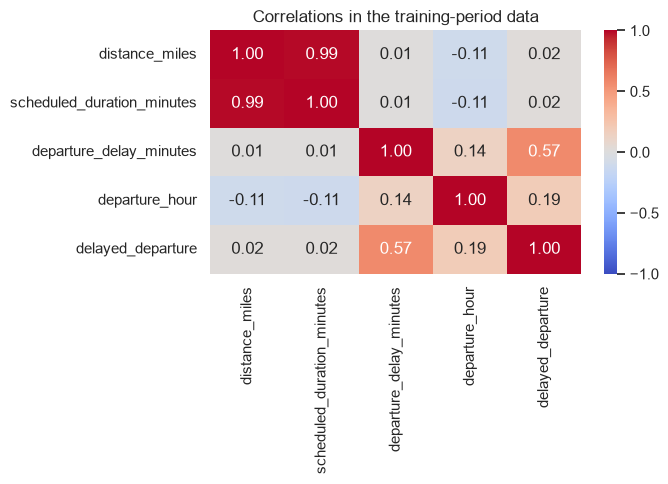

In [36]:
correlation_columns = numeric + ['departure_hour', 'delayed_departure']
correlations = eda[correlation_columns].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlations in the training-period data')
plt.tight_layout()
plt.show()

**What the heatmap shows:** distance and scheduled duration are strongly related (about **0.986**), as longer routes usually take longer. Distance has very little linear association with the delayed target (about **0.019**). Departure hour has a positive association with it (about **0.189**).

Actual delay and the target correlate at about **0.572**, which is expected because the target is defined from actual delay. This does not make actual delay an allowable predictor. Weak correlation also does not prove a feature is useless: relationships can be nonlinear or depend on other variables.

### 2. How are departure delays distributed? — cell [37]

Plot the 10,000-flight EDA sample in 60 bins. The horizontal axis is departure delay in minutes; the vertical axis counts flights in each range.

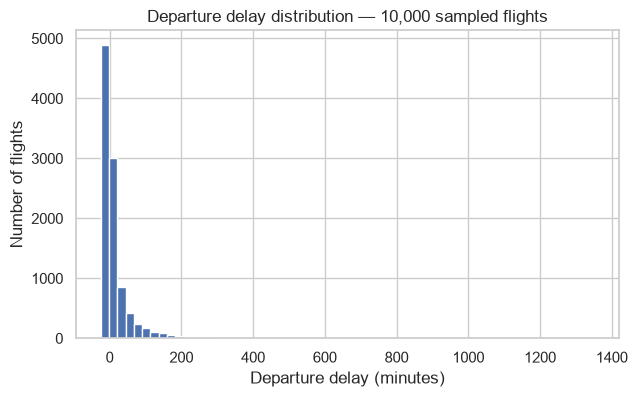

In [37]:
plot_rows['departure_delay_minutes'].plot.hist(bins=60, figsize=(7, 4))
plt.title('Departure delay distribution — 10,000 sampled flights')
plt.xlabel('Departure delay (minutes)')
plt.ylabel('Number of flights')
plt.show()

**What the histogram shows:** many flights depart early or near schedule, while a smaller number have severe delays. These create a long right tail and help explain why the mean exceeds the median.

Negative delays mean early departures. Keep valid extreme delays rather than deleting them simply because they are unusual.

### 3. Does distance separate delayed and on-time flights? — cell [38]

Compare distance for target 0 (under 15 minutes late) and target 1 (at least 15 minutes late) using the same 10,000-flight EDA sample. A boxplot shows the median, middle half of the values, and points beyond its whiskers. Such points are statistically unusual, not automatically errors.

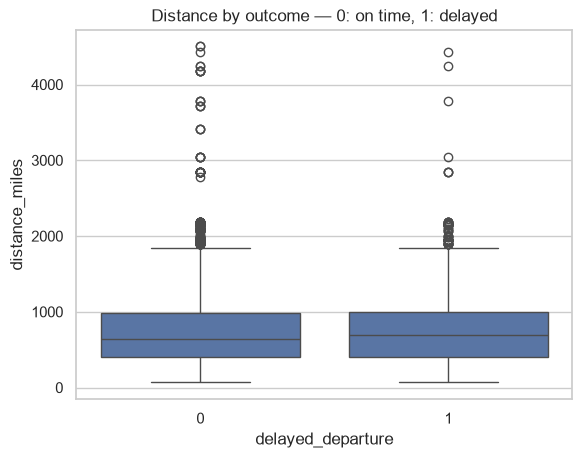

In [38]:
sns.boxplot(data=plot_rows, x='delayed_departure', y='distance_miles')
plt.title('Distance by outcome — 0: on time, 1: delayed')
plt.show()

**What the boxplot shows:** the distance distributions overlap substantially. Distance alone cannot clearly separate the two outcomes.

### 4. How does the delay rate vary during the day? — cell [39]

This is an aggregation: `groupby('departure_hour')` groups the full EDA subset by scheduled local hour. Taking the mean of the 0/1 target gives the fraction delayed. For example, `[0, 1, 0, 1, 0]` has a mean of 0.40, or a 40% delay rate.

Compare rates rather than raw counts, because busy hours have more flights overall. Plot one bar per observed hour.

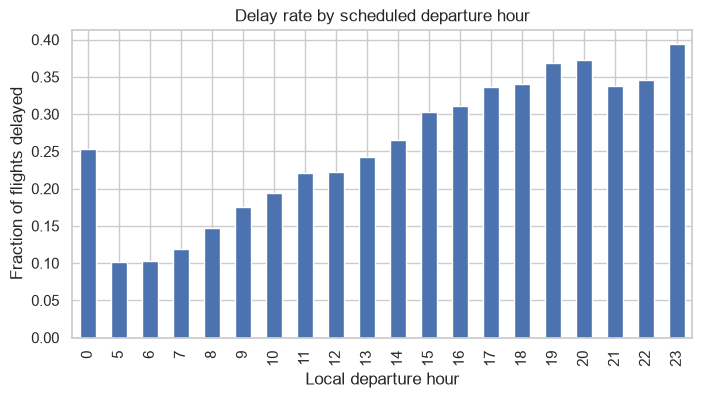

In [39]:
hourly_delay = eda.groupby('departure_hour')['delayed_departure'].mean()
hourly_delay.plot.bar(figsize=(8, 4), title='Delay rate by scheduled departure hour')
plt.xlabel('Local departure hour')
plt.ylabel('Fraction of flights delayed')
plt.show()

**What the hourly chart shows:** delay rates are generally higher later in the day, though the increase is not perfectly steady. The current rates are about **10.3% at 06:00, 22.2% at 12:00, 34.1% at 18:00, 37.2% at 20:00, and 39.4% at 23:00**.

These patterns describe associations, not causes. Sample sizes also vary: the 23:00 rate uses 2,730 flights, while 20:00 uses 40,211.

### What this notebook contributes

The completed flow is **raw files → three-airport table with stable IDs → validated types and labels → comparable timestamps and basic features → saved clean table → four EDA graphs**.

The main findings are class imbalance, a long tail of severe delays, strong overlap between distance and duration, weak separation by distance alone, and generally higher delay rates later in the day.

This notebook prepares data and findings; it produces no model score. Notebook 02 adds weather joins, earlier-delay aggregations, and traffic features. Notebook 03 trains the models, and Notebook 04 evaluates them.

Continue to [02 — Feature Engineering](02_feature_engineering.ipynb).

CLEANED DATA

In [1]:
from pathlib import Path
import pandas as pd

data_dir = Path(
    "/Users/aaditrangnekar/Desktop/departure-delay-classification/data/processed"
)

# Cleaned flight data
flights = pd.read_parquet(data_dir / "flights_clean.parquet")

# Engineered features
features = pd.read_parquet(data_dir / "features.parquet")

print("Flights:", flights.shape)
print("Features:", features.shape)

flights.head()

Flights: (1374996, 33)
Features: (1158165, 55)


,flight_date,airline,flight_number,origin,destination,scheduled_departure_hhmm,departure_delay_minutes,departure_delay_15_source,cancelled,diverted,...,distance_miles_invalid,scheduled_duration_minutes_invalid,month,weekday,departure_hour,departure_time_band,departure_sin,departure_cos,month_sin,month_cos
0,2024-11-21,OO,3629,ATL,SHV,1320.0,-5.0,0.0,0.0,0.0,...,0,0,11,3,13,12–17 afternoon,-0.342020,-0.939693,-0.866025,0.5
1,2024-11-21,OO,3645,ATL,SHV,2203.0,-8.0,0.0,0.0,0.0,...,0,0,11,3,22,18–23 evening,-0.488621,0.872496,-0.866025,0.5
2,2024-11-21,OO,3702,ATL,CRW,855.0,-4.0,0.0,0.0,0.0,...,0,0,11,3,8,06–11 morning,0.722364,-0.691513,-0.866025,0.5
3,2024-11-21,OO,3760,ATL,BQK,1045.0,-5.0,0.0,0.0,0.0,...,0,0,11,3,10,06–11 morning,0.321439,-0.946930,-0.866025,0.5
4,2024-11-21,OO,3810,ATL,CRW,2132.0,-6.0,0.0,0.0,0.0,...,0,0,11,3,21,18–23 evening,-0.601815,0.798636,-0.866025,0.5
